In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define project directories
DATA_DIR = Path("../data/raw")
REPORT_DIR = Path("../reports")

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Load datasets
transactions = pd.read_csv(
    DATA_DIR / "customer_transaction_data.csv"
)

campaigns = pd.read_csv(
    DATA_DIR / "campaign_data.csv"
)

train = pd.read_csv(
    DATA_DIR / "train.csv"
)

# Display dataset dimensions
print("Transaction dataset shape:", transactions.shape)
print("Campaign dataset shape:", campaigns.shape)
print("Training dataset shape:", train.shape)

# Display first five transaction records
display(transactions.head())

Transaction dataset shape: (1324566, 7)
Campaign dataset shape: (28, 4)
Training dataset shape: (78369, 5)


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0


In [2]:
# Display transaction dataset columns
print("Transaction Columns:")
print(transactions.columns.tolist())

# Inspect data types and non-null values
print("\nTransaction Dataset Information:")
transactions.info()

# Display descriptive statistics
print("\nNumerical Summary:")
display(transactions.describe())

# Check missing values
print("\nMissing Values:")
missing_values = pd.DataFrame({
    "missing_count": transactions.isnull().sum(),
    "missing_percentage": (
        transactions.isnull().mean() * 100
    ).round(2)
})

display(missing_values)

# Display the first five records
print("\nSample Transaction Records:")
display(transactions.head())

Transaction Columns:
['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']

Transaction Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1324566 entries, 0 to 1324565
Data columns (total 7 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   date             1324566 non-null  str    
 1   customer_id      1324566 non-null  int64  
 2   item_id          1324566 non-null  int64  
 3   quantity         1324566 non-null  int64  
 4   selling_price    1324566 non-null  float64
 5   other_discount   1324566 non-null  float64
 6   coupon_discount  1324566 non-null  float64
dtypes: float64(3), int64(3), str(1)
memory usage: 83.4 MB

Numerical Summary:


,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
count,1.324566e+06,1.324566e+06,1.324566e+06,1.324566e+06,1.324566e+06,1.324566e+06
mean,8.040020e+02,2.951903e+04,1.306633e+02,1.146036e+02,-1.776871e+01,-5.948983e-01
std,4.573363e+02,1.790806e+04,1.311545e+03,1.529053e+02,3.788867e+01,7.069367e+00
min,1.000000e+00,1.000000e+00,1.000000e+00,3.600000e-01,-3.120310e+03,-1.992230e+03
25%,4.180000e+02,1.468400e+04,1.000000e+00,4.916000e+01,-2.315000e+01,0.000000e+00
50%,8.010000e+02,2.659700e+04,1.000000e+00,7.801000e+01,-1.780000e+00,0.000000e+00
75%,1.198000e+03,4.240575e+04,1.000000e+00,1.243100e+02,0.000000e+00,0.000000e+00
max,1.582000e+03,7.406600e+04,8.963800e+04,1.780964e+04,0.000000e+00,0.000000e+00



Missing Values:


,missing_count,missing_percentage
date,0,0.0
customer_id,0,0.0
item_id,0,0.0
quantity,0,0.0
selling_price,0,0.0
other_discount,0,0.0
coupon_discount,0,0.0



Sample Transaction Records:


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0


In [3]:
# Select available price and discount columns
price_discount_cols = [
    col for col in [
        "selling_price",
        "other_discount",
        "coupon_discount",
        "quantity"
    ]
    if col in transactions.columns
]

# Display descriptive statistics
print("Price and Discount Summary:")
display(transactions[price_discount_cols].describe().round(2))

# Check the number of zero and negative values
print("\nZero and Negative Values:")

for col in price_discount_cols:
    print(f"\n{col}")
    print("Zero values:", (transactions[col] == 0).sum())
    print("Negative values:", (transactions[col] < 0).sum())

# Calculate total missing values in these columns
print("\nMissing Values:")
display(transactions[price_discount_cols].isnull().sum())

Price and Discount Summary:


,selling_price,other_discount,coupon_discount,quantity
count,1324566.00,1324566.00,1324566.00,1324566.00
mean,114.60,-17.77,-0.59,130.66
std,152.91,37.89,7.07,1311.55
min,0.36,-3120.31,-1992.23,1.00
25%,49.16,-23.15,0.00,1.00
50%,78.01,-1.78,0.00,1.00
75%,124.31,0.00,0.00,1.00
max,17809.64,0.00,0.00,89638.00



Zero and Negative Values:

selling_price
Zero values: 0
Negative values: 0

other_discount
Zero values: 652917
Negative values: 671649

coupon_discount
Zero values: 1303280
Negative values: 21286

quantity
Zero values: 0
Negative values: 0

Missing Values:


selling_price      0
other_discount     0
coupon_discount    0
quantity           0
dtype: int64

In [4]:
# Display columns that may contain date information
date_columns = [
    col for col in transactions.columns
    if "date" in col.lower()
]

print("Date columns found:", date_columns)

# Count unique customers
print(
    "\nUnique customers:",
    transactions["customer_id"].nunique()
)

# Count unique items
print(
    "Unique items:",
    transactions["item_id"].nunique()
)

# Transactions per customer
customer_activity = (
    transactions.groupby("customer_id")
    .size()
    .reset_index(name="transaction_records")
)

print("\nCustomer Activity Summary:")
display(customer_activity["transaction_records"].describe().round(2))

# Display the 10 customers with the most transaction records
print("\nTop 10 Customers by Transaction Record Count:")
display(
    customer_activity.sort_values(
        "transaction_records",
        ascending=False
    ).head(10)
)

Date columns found: ['date']

Unique customers: 1582
Unique items: 74063

Customer Activity Summary:


count    1582.00
mean      837.27
std       604.53
min        79.00
25%       416.00
50%       664.00
75%      1078.50
max      4522.00
Name: transaction_records, dtype: float64


Top 10 Customers by Transaction Record Count:


,customer_id,transaction_records
1554,1555,4522
710,711,4173
463,464,4134
1474,1475,3945
1010,1011,3862
910,911,3600
1465,1466,3443
626,627,3429
59,60,3328
897,898,3248


In [5]:
# Count exact duplicate rows
exact_duplicates = transactions.duplicated().sum()

print("Total transaction records:", len(transactions))
print("Exact duplicate rows:", exact_duplicates)

print(
    "Duplicate percentage:",
    round(exact_duplicates / len(transactions) * 100, 2),
    "%"
)

# Display a sample of duplicate rows
print("\nSample Duplicate Records:")

duplicate_rows = transactions[
    transactions.duplicated(keep=False)
]

display(duplicate_rows.head(10))

# Check repeated customer-item combinations
customer_item_duplicates = transactions.duplicated(
    subset=["customer_id", "item_id"],
    keep=False
).sum()

print(
    "\nRows belonging to repeated customer-item combinations:",
    customer_item_duplicates
)

Total transaction records: 1324566
Exact duplicate rows: 2916
Duplicate percentage: 0.22 %

Sample Duplicate Records:


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
5463,2012-01-19,801,32650,3,213.72,-159.22,0.0
5465,2012-01-19,801,32650,3,213.72,-159.22,0.0
5491,2012-01-19,814,25251,2,163.14,0.00,0.0
5493,2012-01-19,814,57670,2,21.37,0.00,0.0
5497,2012-01-19,814,25251,2,163.14,0.00,0.0
5502,2012-01-19,814,57670,2,21.37,0.00,0.0
5508,2012-01-19,433,34474,1,89.05,-17.45,0.0
5514,2012-01-19,433,34474,1,89.05,-17.45,0.0
6027,2012-01-20,1140,28197,1,106.50,0.00,0.0
6038,2012-01-20,1140,28197,1,106.50,0.00,0.0



Rows belonging to repeated customer-item combinations: 730909


Discount Summary:


,coupon_discount,other_discount
count,1324566.00,1324566.00
mean,-0.59,-17.77
std,7.07,37.89
min,-1992.23,-3120.31
25%,0.00,-23.15
50%,0.00,-1.78
75%,0.00,0.00
max,0.00,0.00



--- coupon_discount ---
Zero values: 1303280
Positive values: 0
Negative values: 21286

--- other_discount ---
Zero values: 652917
Positive values: 0
Negative values: 671649


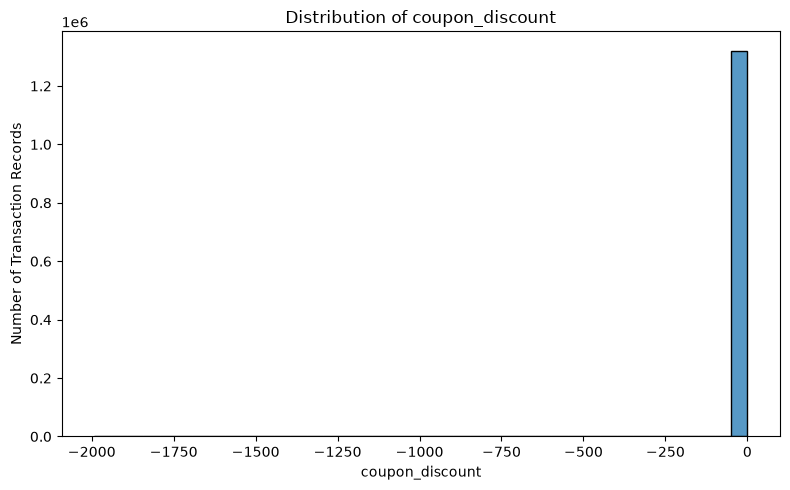

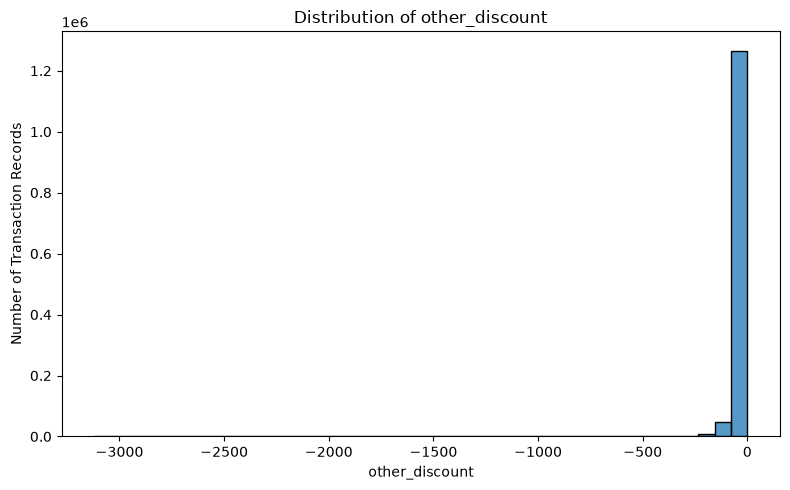

In [6]:
# Calculate discount statistics
discount_columns = [
    col for col in ["coupon_discount", "other_discount"]
    if col in transactions.columns
]

print("Discount Summary:")
display(transactions[discount_columns].describe().round(2))

# Count zero, positive, and negative values
for col in discount_columns:
    print(f"\n--- {col} ---")
    print("Zero values:", (transactions[col] == 0).sum())
    print("Positive values:", (transactions[col] > 0).sum())
    print("Negative values:", (transactions[col] < 0).sum())

# Visualize discount distributions
for col in discount_columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=transactions, x=col, bins=40)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Transaction Records")
    plt.tight_layout()
    plt.show()

Correlation Matrix:


,selling_price,coupon_discount,other_discount,quantity
selling_price,1.000,-0.080,-0.246,0.673
coupon_discount,-0.080,1.000,0.110,0.008
other_discount,-0.246,0.110,1.000,-0.057
quantity,0.673,0.008,-0.057,1.000


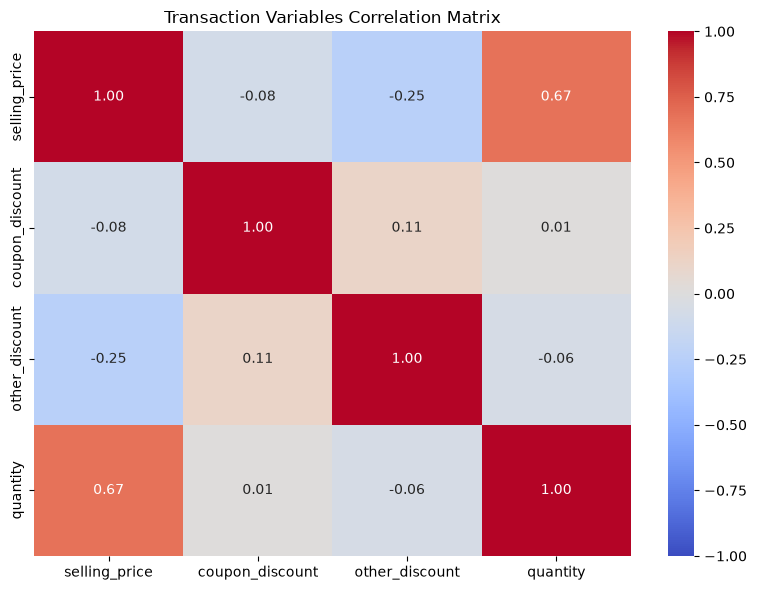

In [7]:
# Calculate correlations between numerical transaction variables
analysis_columns = [
    col for col in [
        "selling_price",
        "coupon_discount",
        "other_discount",
        "quantity"
    ]
    if col in transactions.columns
]

correlation_matrix = transactions[analysis_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(3))

# Visualize correlations
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Transaction Variables Correlation Matrix")
plt.tight_layout()
plt.show()

In [8]:
# 1. Save transaction descriptive statistics
transaction_summary = transactions.describe().T
transaction_summary.to_csv(
    REPORT_DIR / "day06_transaction_summary.csv"
)

# 2. Save missing-value analysis
transaction_missing = pd.DataFrame({
    "missing_count": transactions.isnull().sum(),
    "missing_percentage": (
        transactions.isnull().mean() * 100
    ).round(2)
})

transaction_missing.to_csv(
    REPORT_DIR / "day06_missing_values.csv"
)

# 3. Save duplicate analysis
duplicate_summary = pd.DataFrame({
    "metric": [
        "total_records",
        "exact_duplicate_rows",
        "duplicate_percentage",
        "repeated_customer_item_rows"
    ],
    "value": [
        len(transactions),
        int(transactions.duplicated().sum()),
        round(
            transactions.duplicated().sum()
            / len(transactions) * 100, 2
        ),
        int(customer_item_duplicates)
    ]
})

duplicate_summary.to_csv(
    REPORT_DIR / "day06_duplicate_analysis.csv",
    index=False
)

# 4. Save discount correlation matrix
correlation_matrix.to_csv(
    REPORT_DIR / "day06_discount_correlation.csv"
)

print("Day 6 reports saved successfully!")

print("\nSaved files:")
for file in sorted(REPORT_DIR.glob("day06_*.csv")):
    print(file.name)

Day 6 reports saved successfully!

Saved files:
day06_discount_correlation.csv
day06_duplicate_analysis.csv
day06_missing_values.csv
day06_transaction_summary.csv
